### Computing long duration gamma ray bursts from double compact objects population

In [5]:
from posydon.popsyn.synthetic_population import Population

file = '../Generated_Tuto_Data/BBH_contact.h5'

In [6]:
BBH_population = Population(file)
BBH_population.mass_per_metallicity

Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


,simulated_mass,simulated_mass_single,simulated_mass_binaries,number_of_systems
metallicity,,,,
0.001,27552.574773,0.0,27552.574773,10
0.010,28011.381319,0.0,28011.381319,9
0.100,28284.732479,0.0,28284.732479,6
0.200,27887.615202,0.0,27887.615202,1
1.000,27592.480099,0.0,27592.480099,1
2.000,28643.951953,0.0,28643.951953,3


In [7]:
BBH_population.calculate_formation_channels(mt_history=True)

Formation channels already exist in the parsed population file!
Channels will be overwriten


In [8]:
# Index from 0 to 29

# To chec kthe number of indexes that are in the DataFrame history :
# BBH_population.history.select(columns=[]).index

BBH_population.history[16]

,state,event,time,orbital_period,eccentricity,lg_mtransfer_rate,step_names,step_times,S1_state,S1_mass,...,S2_he_core_mass,S2_he_core_radius,S2_co_core_mass,S2_co_core_radius,S2_center_h1,S2_center_he4,S2_surface_h1,S2_surface_he4,S2_surf_avg_omega_div_omega_crit,S2_spin
binary_index,,,,,,,,,,,,,,,,,,,,,
16,detached,ZAMS,0.000000e+00,4.038385e+01,0.000000,NaN,initial_cond,0.000000,H-rich_Core_H_burning,114.784952,...,NaN,NaN,NaN,NaN,0.750986,2.490000e-01,NaN,NaN,NaN,NaN
16,contact,oDoubleCE2,2.952403e+06,4.896151e+01,0.000000,-2.575113,step_HMS_HMS,0.072873,H-rich_Shell_H_burning,92.111551,...,50.315416,1.03874,0.000000,0.000000,0.005572,9.903530e-01,6.943473e-01,0.305630,0.628614,1.791363
16,detached,NaN,2.952403e+06,1.719760e+00,0.000000,NaN,step_CE,0.000221,stripped_He_non_burning,50.717383,...,50.315416,1.03874,0.000000,0.000000,0.005572,9.903530e-01,1.000000e-02,0.989986,NaN,NaN
16,detached,CC1,3.205015e+06,1.851920e+00,0.000000,NaN,step_detached,2.480303,stripped_He_Core_He_depleted,47.415250,...,46.770907,NaN,42.943977,0.945833,0.000000,8.314416e-02,1.000000e-99,0.999986,0.006081,0.050470
16,detached,NaN,3.205015e+06,1.897154e+00,0.016894,NaN,step_SN,0.027692,BH,46.915250,...,46.770907,NaN,42.943977,0.945833,0.000000,8.314416e-02,1.000000e-99,0.999986,0.006081,0.050470
16,detached,CC2,3.251249e+06,1.907292e+00,0.016893,NaN,step_detached,0.453329,BH,46.915250,...,46.516768,NaN,42.963379,0.260346,0.000000,7.269017e-12,1.000000e-99,0.999986,0.014922,0.032813
16,detached,NaN,3.251249e+06,1.856408e+00,0.014663,NaN,step_SN,0.027726,BH,46.915250,...,NaN,NaN,42.963379,NaN,NaN,NaN,NaN,NaN,NaN,0.033483
16,contact,CO_contact,5.168013e+08,9.420217e-08,0.000000,NaN,step_dco,0.858115,BH,46.915250,...,NaN,NaN,42.963379,NaN,NaN,NaN,NaN,NaN,NaN,0.033483
16,contact,END,5.168013e+08,9.420217e-08,0.000000,NaN,step_end,0.000062,BH,46.915250,...,NaN,NaN,42.963379,NaN,NaN,NaN,NaN,NaN,NaN,0.033483


POSYDON already includes a basic selection function for GRBs named GRB_selection in the posydon.popsyn.transient_select_funcs module, which identifies if a GRB occurred based on the presence of m_disk_radiated for either star

In [9]:
from posydon.popsyn.transient_select_funcs import GRB_selection

GRB_selection(BBH_population.history[15],
              BBH_population.oneline[15],
              BBH_population.formation_channels.loc[[15]],
              S1_S2='S2')

""


In [10]:
import pandas as pd

def GRB_wrapper(transient_chunk, oneline_chunk, formation_channels_chunk):
    """calculate the GRBs from star 1 and star 2 for a given chunk of the population"""
    # select potential GRBs from star 1
    df_1 = GRB_selection(transient_chunk, oneline_chunk, formation_channels_chunk, S1_S2='S1')
    # select potential GRBs from star 2
    df_2 = GRB_selection(transient_chunk, oneline_chunk, formation_channels_chunk, S1_S2='S2')

    # combine the two dataframes
    if df_1 is not None and df_2 is not None:
        GRB_df = pd.concat([df_1, df_2])
    elif df_1 is not None:
        GRB_df = df_1
    elif df_2 is not None:
        GRB_df = df_2
    else:
        return None

    return GRB_df

In [11]:
LGRB = BBH_population.create_transient_population(GRB_wrapper, 'LGRB')

overwriting transient population
Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


- For now, let’s continue and calculate the metallicity bias function for the LGRBs. We need to recalculate the model_weights for this new population.

In [12]:
pop_params = LGRB.ini_params.copy()

# Extending the IMF to higher and lower masses
pop_params['primary_mass_min'] = 0.01
pop_params['primary_mass_max'] = 200

# Use a flat mass ratio distribution
pop_params['q_min'] = 0
pop_params['q_max'] = 1

# Binary fraction
pop_params['binary_fraction_const'] = 0.7

# model_weights_identifier is an arbitrary name for the set of weights
# you are calculating. You can use it to keep track of different
# sets of weights you might want to calculate.
LGRB.calculate_model_weights(model_weights_identifier='extended_IMF',
                                population_parameters=pop_params)

/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/distributions.py:266: RuntimeWarning: invalid value encountered in power
/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/distributions.py:266: RuntimeWarning: invalid value encountered in power
/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/distributions.py:266: RuntimeWarning: invalid value encountered in power
/home/users/a/aguetar1/.conda/envs/posydon_env/lib/python3.11/site-packages/posydon/popsyn/distributions.py:266: RuntimeWarning: invalid value encountered in power


,extended_IMF
0,0.000006
3,0.000006
7,0.000006
8,0.000006
11,0.000006
12,0.000006
23,0.000006
29,0.000006
1,0.000006
12,0.000006


In [15]:
LGRB.efficiency('extended_IMF')

,total
metallicity,
0.001,0.000012
0.010,0.00003
0.100,0.000018
0.200,0.0
1.000,0.0
2.000,0.000006


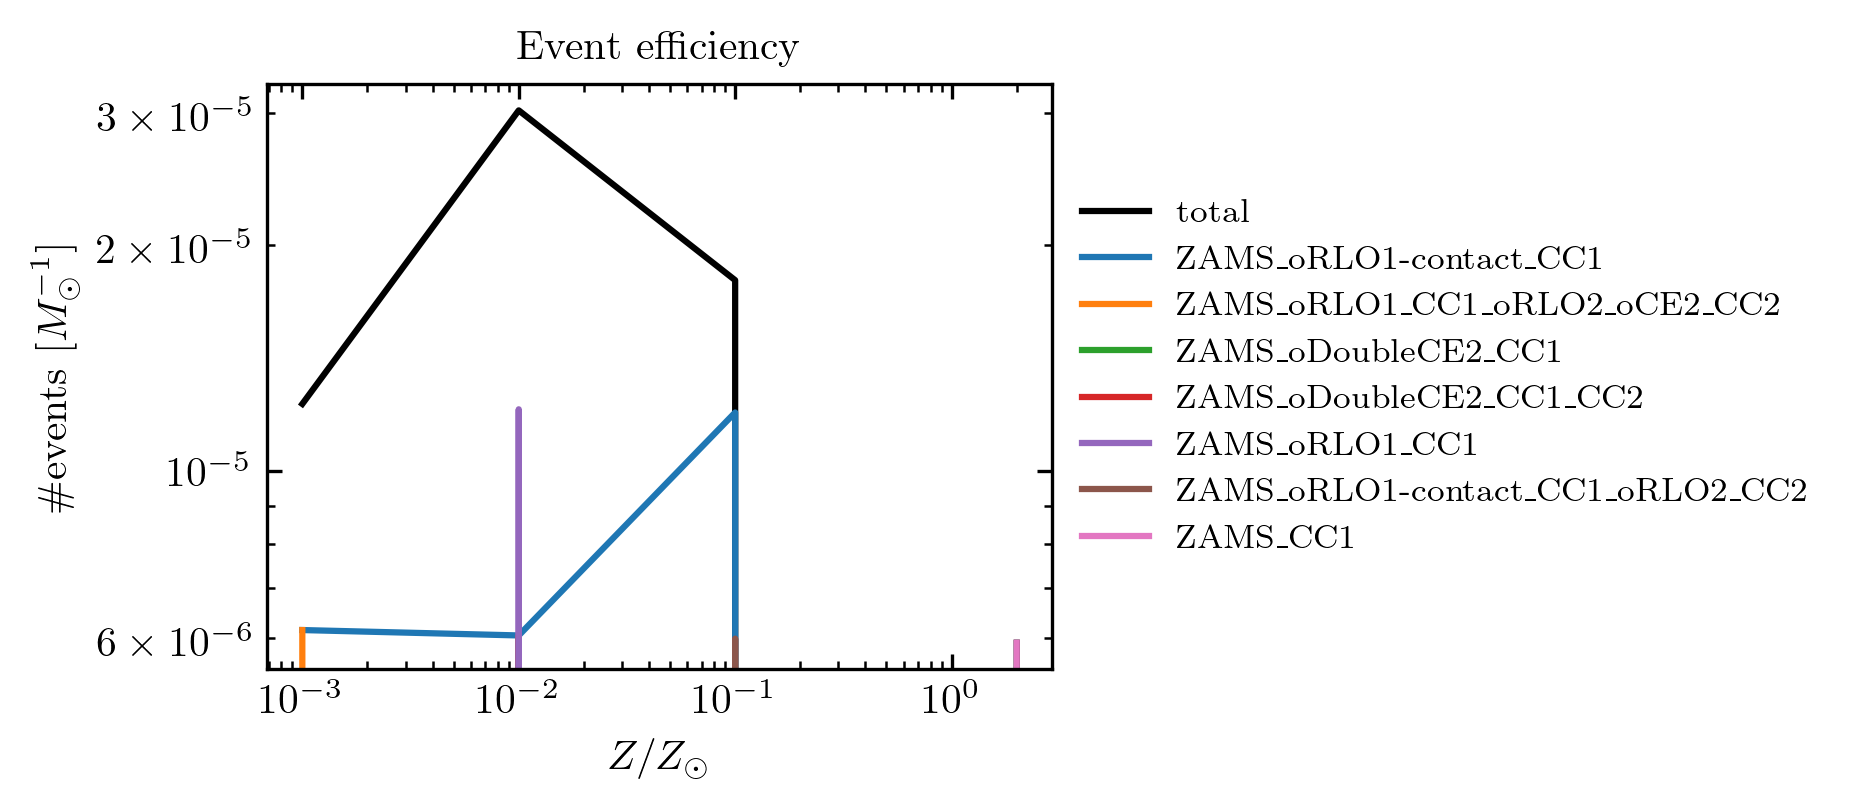

In [16]:
LGRB.plot_efficiency_over_metallicity('extended_IMF', channels=True)

#fig = plt.gcf()
#fig.savefig('LGRB_efficiency_extended_IMF.png', dpi=300)
#plt.close(fig)

After this selection, we follow similar steps to the BBH analysis for creating and plotting a cosmic star formation history weighted rate.

In [17]:
LGRB_rates = LGRB.calculate_cosmic_weights('IllustrisTNG',
                                           model_weights='extended_IMF')

Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


In [18]:
LGRB_rates.calculate_intrinsic_rate_density(channels=True)

,total,ZAMS_CC1,ZAMS_oDoubleCE2_CC1,ZAMS_oDoubleCE2_CC1_CC2,ZAMS_oRLO1-contact_CC1,ZAMS_oRLO1-contact_CC1_oRLO2_CC2,ZAMS_oRLO1_CC1,ZAMS_oRLO1_CC1_oRLO2_oCE2_CC2
0.000000,26.693976,25.169798,0.028746,0.028572,0.987839,0.423592,0.054879,0.000550
0.006963,35.819355,33.717590,0.032246,0.032185,1.341957,0.630412,0.063550,0.001414
0.013998,37.208299,34.957198,0.031881,0.031845,1.436159,0.686008,0.063205,0.002003
0.021105,37.972839,35.655733,0.033144,0.033117,1.474444,0.708648,0.065874,0.001878
0.028287,38.879105,36.471733,0.036081,0.036059,1.526449,0.735611,0.071813,0.001360
...,...,...,...,...,...,...,...,...
9.627349,60.657103,0.000000,4.807086,4.806619,28.578759,10.870492,9.606868,1.987279
11.337550,21.125825,0.000000,2.043483,2.043257,9.156649,3.300127,4.083439,0.498870
13.957133,2.020094,0.000000,0.279339,0.279302,0.649278,0.114984,0.558104,0.139086
18.630504,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [20]:
from posydon.popsyn.synthetic_population import Rates
BBH_rates  = Rates('../Generated_Tuto_Data/BBH_contact.h5', 'BBH', 'IllustrisTNG')

Missing ini parameter: orbital_separation_scheme
Missing ini parameter: orbital_separation_min
Missing ini parameter: orbital_separation_max


In [21]:
BBH_rates.intrinsic_rate_density

,total,ZAMS_CC1_oRLO2_oCE2_CC2_END,ZAMS_oDoubleCE1_CC1_CC2_END,ZAMS_oDoubleCE2_CC1_CC2_END,ZAMS_oRLO1-contact_CC1_CC2_END,ZAMS_oRLO1-contact_CC1_oRLO2_CC2_END,ZAMS_oRLO1_CC1_oRLO2_CC2_END,ZAMS_oRLO1_CC1_oRLO2_oCE2_CC2_END
0.000000,259.575413,78.832398,0.047294,0.049951,19.394367,3.594430,21.739072,135.917901
0.006963,250.833026,76.417168,0.071639,0.460926,31.154644,21.484224,20.222830,101.021594
0.013998,247.321129,76.068969,0.078427,0.641742,33.361083,28.658551,16.533126,91.979230
0.021105,253.278315,77.197001,0.074164,0.746250,34.490012,33.960256,18.330012,88.480619
0.028287,252.756208,79.258889,0.075829,0.798085,35.541599,36.935200,13.208165,86.938441
...,...,...,...,...,...,...,...,...
9.627349,5.488821,0.000000,0.000000,0.283170,0.000000,0.000000,0.000000,5.205651
11.337550,2.132099,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.132099
13.957133,0.270386,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.270386
18.630504,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


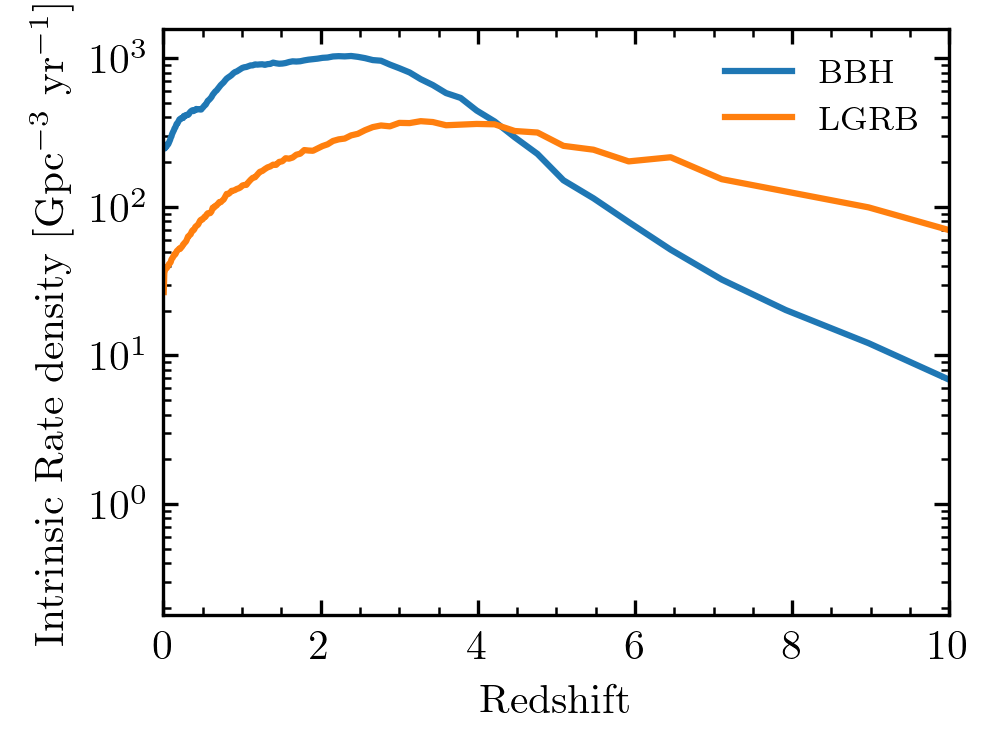

In [23]:
import matplotlib.pyplot as plt
plt.plot(BBH_rates.centers_redshift_bins, BBH_rates.intrinsic_rate_density['total'], label='BBH')
plt.plot(LGRB_rates.centers_redshift_bins, LGRB_rates.intrinsic_rate_density['total'], label='LGRB')

plt.yscale("log")
plt.xlim(0,10)
plt.xlabel('Redshift')
plt.ylabel('Intrinsic Rate density [Gpc$^{-3}$ yr$^{-1}$]')
plt.legend()
plt.show()

In [24]:
LGRB_rates.population

,orbital_period_preSN,orbital_period_postSN,eccentricity_preSN,eccentricity_postSN,S1_spin_preSN,S1_spin_postSN,S2_spin_preSN,S2_spin_postSN,S1_mass_preSN,S1_mass_postSN,...,mt_history_CO_HeMS_RLO,FAILED,WARNING,metallicity,channel,time,S2_mass_preSN,S2_mass_postSN,S1_mass,S2_m_disk_radiated
0,4.052487,4.573359,0.000000,0.073560,0.129392,0.124608,2.967284,2.967284,15.691420,14.983747,...,NaN,0,1,0.100,ZAMS_oRLO1-contact_CC1,6.477515,NaN,NaN,NaN,NaN
3,4.661588,4.765903,0.000000,0.039764,0.111056,0.082709,2.859439,2.859439,16.930726,15.637907,...,NaN,0,1,0.100,ZAMS_oRLO1-contact_CC1,6.131783,NaN,NaN,NaN,NaN
7,3.653182,4.079972,0.000000,0.065579,0.104538,0.011714,3.767797,3.767797,35.679516,33.392341,...,NaN,0,1,0.010,ZAMS_oRLO1_CC1,4.320658,NaN,NaN,NaN,NaN
8,2.713925,3.219982,0.000000,0.106626,0.111009,0.019599,3.470917,3.470917,19.123711,16.925698,...,NaN,0,1,0.010,ZAMS_oRLO1-contact_CC1,6.128373,NaN,NaN,NaN,NaN
11,5.214826,4.662308,0.000000,0.091319,0.098024,0.007374,6.944707,6.944707,13.826507,12.120482,...,NaN,0,1,0.010,ZAMS_oRLO1_CC1,7.786775,NaN,NaN,NaN,NaN
12,0.655253,0.733682,0.000000,0.068675,0.392679,0.372247,0.795224,0.795224,20.366066,19.851910,...,NaN,0,1,0.010,ZAMS_oDoubleCE2_CC1,4.986313,NaN,NaN,NaN,NaN
23,2.338399,2.328858,0.000000,0.038100,0.138805,0.014266,6.204028,6.204028,20.837893,18.958399,...,NaN,0,1,0.001,ZAMS_oRLO1-contact_CC1,5.675261,NaN,NaN,NaN,NaN
29,315.024413,298.102839,0.000000,0.304748,0.085506,0.077975,0.191633,0.191633,9.283058,5.908580,...,NaN,0,1,2.000,ZAMS_CC1,3.785356,NaN,NaN,NaN,NaN
1,2.490121,1.941496,0.000000,0.186417,0.032840,0.032840,0.233392,0.175465,NaN,NaN,...,NaN,0,1,0.100,ZAMS_oRLO1-contact_CC1_oRLO2_CC2,8.945085,13.271535,13.132261,12.354878,0.000444
12,0.750697,0.721815,0.068267,0.047549,0.372247,0.372247,0.390590,0.382528,NaN,NaN,...,NaN,0,1,0.010,ZAMS_oDoubleCE2_CC1_CC2,5.122498,18.403868,17.888463,19.851910,0.015404


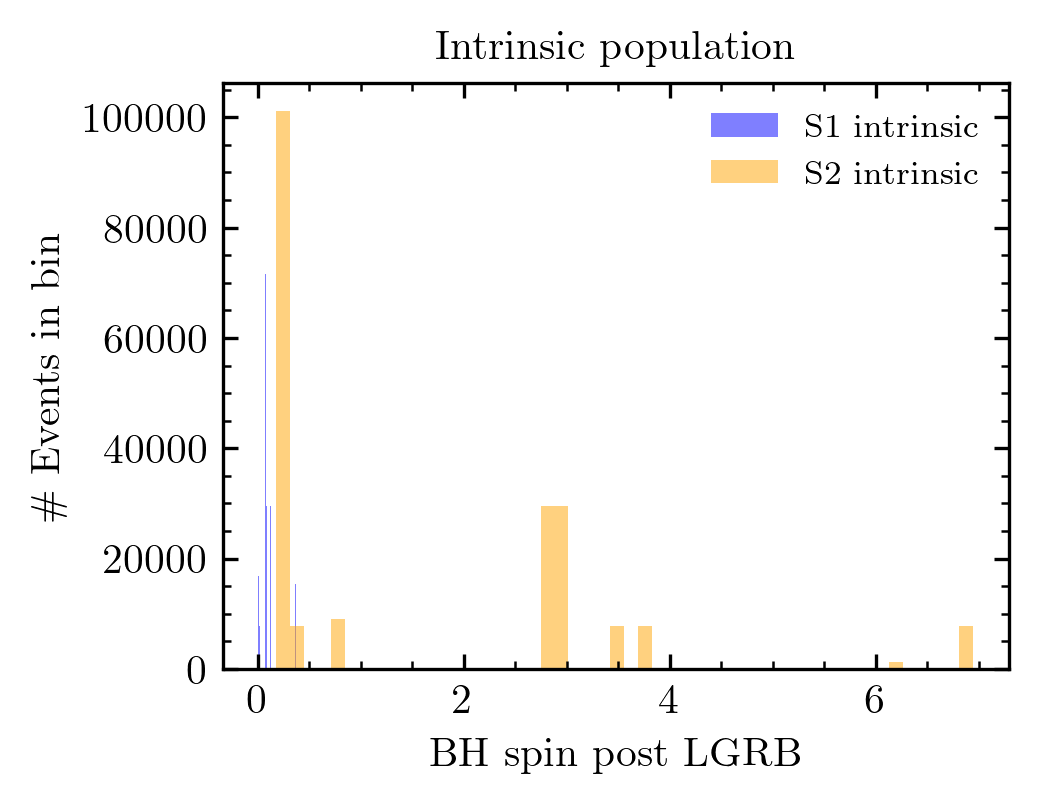

In [25]:
fig, ax = plt.subplots(1,1)
LGRB_rates.plot_hist_properties('S1_spin_postSN', intrinsic=True, label='S1', color='blue', ax=ax, show=False)
LGRB_rates.plot_hist_properties('S2_spin_postSN', intrinsic=True, label='S2', color='orange', ax=ax, show=False)
ax.legend()
ax.set_xlabel('BH spin post LGRB')
ax.set_ylabel('\# Events in bin')
plt.show()